# Second hand store sales forecast

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from sklearn.ensemble import GradientBoostingRegressor

## 2. Settings and connection

In [2]:
DB_URL = "postgresql+psycopg2://lauralukasevic@localhost:5432/project3_sql"
engine = create_engine(DB_URL)

START, END = pd.Timestamp("2017-01-01"), pd.Timestamp("2026-11-14")
rng = np.random.default_rng(42)

# name, category, price, base units per month, yearly growth, peak month
PRODUCTS = [
    ("Vintage Denim Jacket", "Clothing", 38, 40, .06, 10), ("Wool Winter Coat", "Clothing", 55, 25, .04, 12),
    ("Summer Dress", "Clothing", 22, 35, .05, 6), ("Leather Boots", "Shoes", 48, 22, .03, 11),
    ("Retro Sneakers", "Shoes", 42, 30, .08, 5), ("Oak Bookshelf", "Furniture", 120, 8, .02, 9),
    ("Mid-century Armchair", "Furniture", 180, 6, .07, 3), ("Vinyl Records Lot", "Media", 25, 28, .09, 12),
    ("Paperback Books Box", "Media", 15, 45, -.02, 8), ("Vintage Camera", "Electronics", 85, 10, .05, 12),
    ("Used Smartphone", "Electronics", 140, 15, .04, 11), ("Ceramic Dinner Set", "Home", 35, 14, .03, 5),
]
COUNTRIES = ["Sweden", "Germany", "Norway", "Finland", "Denmark", "Netherlands", "UK"]

def q(sql):
    """Run a SQL query and return a table."""
    return pd.read_sql(text(sql), engine)

print("Connected to:", q("SELECT current_database() AS db").iloc[0, 0])

Connected to: project3_sql


## 3. Generate the data

In [3]:
def generate():
    products = pd.DataFrame(PRODUCTS, columns=["name", "category", "list_price", "base", "growth", "peak"])
    products.insert(0, "product_id", range(1, len(products) + 1))
    n = 2500
    cust = pd.DataFrame({"customer_id": range(1, n + 1),
        "name": [f"Customer {i}" for i in range(1, n + 1)],
        "email": [f"customer{i}@example.com" for i in range(1, n + 1)],
        "country": rng.choice(COUNTRIES, n, p=[.4, .15, .12, .1, .1, .08, .05]),
        "signup_date": START + pd.to_timedelta(np.sort(rng.integers(0, (END - START).days, n)), "D")})
    signups = cust.signup_date.values
    rows = []
    for m in pd.date_range(START, END, freq="MS"):
        days = min((m + pd.offsets.MonthEnd(0)), END).day
        frac = days / m.days_in_month                      # Note: Nov 2026 is only half a month
        t = (m.year - 2017) + m.month / 12
        covid = .55 if (m.year == 2020 and 3 <= m.month <= 6) else 1.0
        for p in products.itertuples():
            season = 1 + .35 * np.cos(2 * np.pi * (m.month - p.peak) / 12)
            lam = p.base * (1 + p.growth) ** t * season * covid * rng.lognormal(0, .12) * frac
            for d in rng.integers(1, days + 1, rng.poisson(lam)):
                rows.append((m + pd.Timedelta(days=int(d) - 1), p.product_id, p.list_price))
    L = pd.DataFrame(rows, columns=["order_date", "product_id", "price"]).sort_values("order_date", ignore_index=True)
    k = np.searchsorted(signups, L.order_date.values, side="right")   # Note: how many customers had signed up by that date
    L["customer_id"] = (rng.random(len(L)) * np.maximum(k, 1)).astype(int) + 1
    L["order_id"] = L.groupby(["order_date", "customer_id"]).ngroup() + 1
    L["unit_price"] = (L.price * rng.uniform(.85, 1.1, len(L))).round(2)
    items = L.assign(item_id=range(1, len(L) + 1), quantity=1)[["item_id", "order_id", "product_id", "quantity", "unit_price"]]
    orders = L.drop_duplicates("order_id")[["order_id", "customer_id", "order_date"]]
    return cust, products[["product_id", "name", "category", "list_price"]], orders, items

customers, products, orders, order_items = generate()
print(f"customers: {len(customers):,} | products: {len(products)} | orders: {len(orders):,} | items: {len(order_items):,}")
orders.head()

customers: 2,500 | products: 12 | orders: 41,134 | items: 41,563


,order_id,customer_id,order_date
0,1,1,2017-01-01
13,2,1,2017-01-02
16,5,3,2017-01-03
17,3,1,2017-01-03
19,4,2,2017-01-03


## 4. Load into PostgreSQL

In [4]:
SCHEMA = """
DROP TABLE IF EXISTS sales_forecast, order_items, orders, products, customers CASCADE;
CREATE TABLE customers (customer_id INT PRIMARY KEY, name TEXT NOT NULL, email TEXT UNIQUE NOT NULL,
                        country TEXT, signup_date DATE NOT NULL);
CREATE TABLE products (product_id INT PRIMARY KEY, name TEXT NOT NULL, category TEXT NOT NULL,
                       list_price NUMERIC(8,2) CHECK (list_price > 0));
CREATE TABLE orders (order_id INT PRIMARY KEY, customer_id INT REFERENCES customers, order_date DATE NOT NULL);
CREATE TABLE order_items (item_id INT PRIMARY KEY, order_id INT REFERENCES orders,
                          product_id INT REFERENCES products, quantity INT CHECK (quantity > 0),
                          unit_price NUMERIC(8,2));
CREATE INDEX ON orders(order_date);
CREATE INDEX ON order_items(product_id);
"""
with engine.begin() as conn:         
    conn.execute(text(SCHEMA))

for name, df in [("customers", customers), ("products", products), ("orders", orders), ("order_items", order_items)]:
    df.to_sql(name, engine, if_exists="append", index=False, chunksize=5000)

q("""SELECT 'customers' AS table_name, COUNT(*) AS rows FROM customers
     UNION ALL SELECT 'products', COUNT(*) FROM products
     UNION ALL SELECT 'orders', COUNT(*) FROM orders
     UNION ALL SELECT 'order_items', COUNT(*) FROM order_items""")

,table_name,rows
0,customers,2500
1,products,12
2,orders,41134
3,order_items,41563


## 5. Overview charts

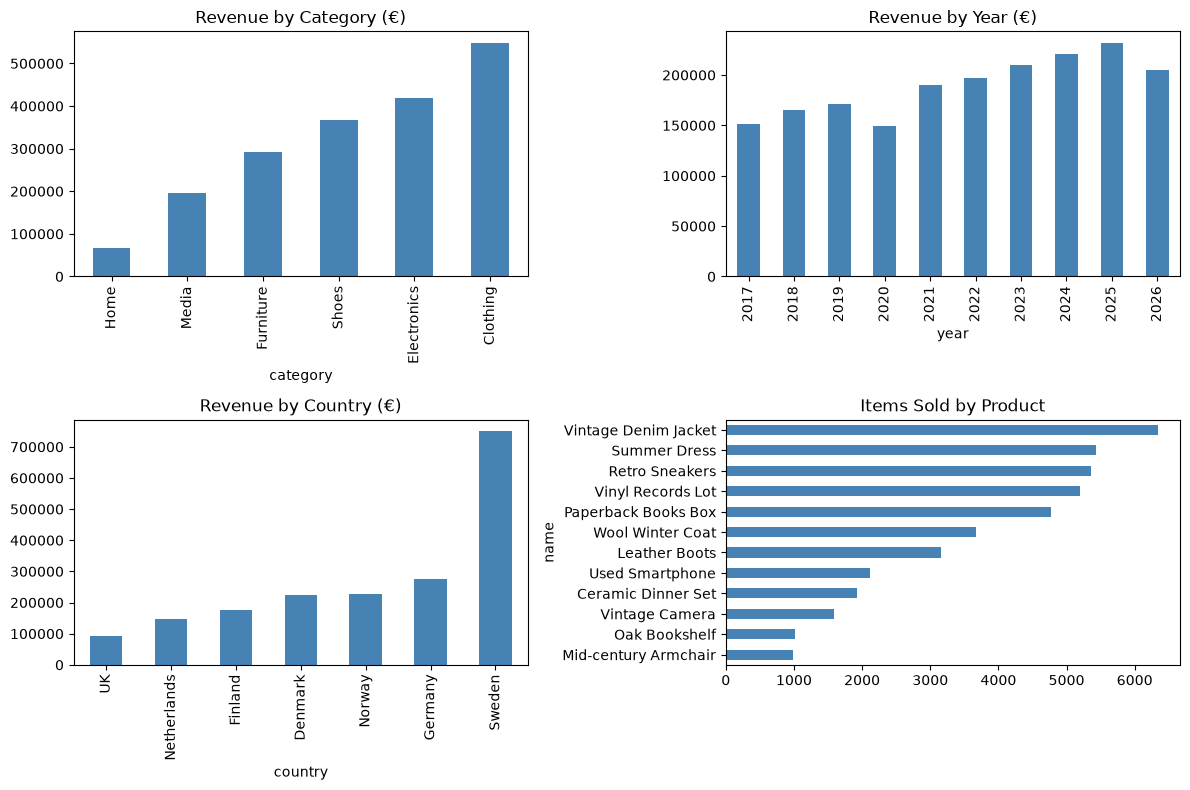

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
REV = "SUM(oi.quantity * oi.unit_price)::float"

q(f"SELECT p.category, {REV} AS revenue FROM order_items oi JOIN products p USING (product_id) GROUP BY 1 ORDER BY 2") \
    .set_index("category").revenue.plot(kind="bar", ax=axes[0, 0], title="Revenue by Category (€)", color="steelblue")

q(f"SELECT EXTRACT(YEAR FROM o.order_date)::int AS year, {REV} AS revenue FROM order_items oi JOIN orders o USING (order_id) GROUP BY 1 ORDER BY 1") \
    .set_index("year").revenue.plot(kind="bar", ax=axes[0, 1], title="Revenue by Year (€)", color="steelblue")

q(f"SELECT c.country, {REV} AS revenue FROM order_items oi JOIN orders o USING (order_id) JOIN customers c USING (customer_id) GROUP BY 1 ORDER BY 2") \
    .set_index("country").revenue.plot(kind="bar", ax=axes[1, 0], title="Revenue by Country (€)", color="steelblue")

q("SELECT p.name, SUM(oi.quantity)::int AS units FROM order_items oi JOIN products p USING (product_id) GROUP BY 1 ORDER BY 2") \
    .set_index("name").units.plot(kind="barh", ax=axes[1, 1], title="Items Sold by Product", color="steelblue")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Forecasting functions (machine learning)
**Note:**
- **Model:** gradient boosting (`GradientBoostingRegressor`): 300 small decision trees, each one fixes the mistakes of the previous ones.
- **Target:** units sold in a month. **Features:** sales 1, 2, 3, 6 and 12 months ago, the average of the last 3 months, the month of the year, a time counter.
- **One model per product**, because each product has its own season and level.
- **Forecasting 12 months:** predict one month, add it to the history, predict the next. Errors can pile up in the far months.
- **Weakness:** trees cannot predict above what they have seen, so growing products tend to be predicted too low.

In [6]:
def features(s):
    """Turn a sales history into a table the model can learn from."""
    d = pd.DataFrame({"y": s.values}, index=s.index)       # y = target: units sold
    for l in (1, 2, 3, 6, 12):                              # Note: lag12 = same month last year -> seasonality
        d[f"lag{l}"] = d.y.shift(l)
    d["roll3"] = d.y.shift(1).rolling(3).mean()             # Note: shift(1) = only past months, no cheating
    d["sin"], d["cos"] = np.sin(2 * np.pi * d.index.month / 12), np.cos(2 * np.pi * d.index.month / 12)  # Note: Dec and Jan are close
    d["t"] = np.arange(len(d))                              # Note: lets the model see the slow trend
    return d

def fit(s):
    """Train one model on one product's history."""
    d = features(s).dropna()                                # Note: first 12 months have no lag12, so drop them
    model = GradientBoostingRegressor(
        n_estimators=300,   # number of trees
        max_depth=3,        # shallow trees = simple rules, less overfitting
        learning_rate=.05,  # small correction steps
        subsample=.8,       # every tree sees a random 80% of the rows
        random_state=0)
    return model.fit(d.drop(columns="y"), d.y)

def forecast(s, horizon=12):
    """Predict the next months one at a time, feeding each prediction back in."""
    model, s = fit(s), s.copy()
    for _ in range(horizon):
        nxt = s.index[-1] + pd.offsets.MonthBegin(1)
        s.loc[nxt] = np.nan
        x = features(s).iloc[[-1]].drop(columns="y")
        s.loc[nxt] = max(0, model.predict(x)[0])            # Note: no negative sales
    return s.iloc[-horizon:]

## 7. Backtest and forecast

In [7]:
monthly = q("""SELECT oi.product_id, date_trunc('month', o.order_date)::date AS month,
       SUM(oi.quantity)::int AS units, SUM(oi.quantity * oi.unit_price)::float AS revenue
FROM order_items oi JOIN orders o USING (order_id) GROUP BY 1, 2 ORDER BY 1, 2""")
monthly["month"] = pd.to_datetime(monthly["month"])
monthly = monthly[monthly.month < "2026-11-01"]

results = []
for p in products.itertuples():
    m = monthly[monthly.product_id == p.product_id]
    s = m.set_index("month").units.asfreq("MS", fill_value=0).astype(float)  # Note: months with no sales must be 0, not missing
    bt = forecast(s.iloc[:-12])                         # Note: trained until Oct 2025, predicts Nov 2025 - Oct 2026
    actual = s.iloc[-12:]
    mape = float((abs(bt.values - actual.values) / actual.clip(lower=1).values).mean() * 100)
    fc = forecast(s)                                    # Note: trained on everything, predicts Nov 2026 - Oct 2027
    price = m.tail(12).revenue.sum() / m.tail(12).units.sum()
    results.append(dict(id=p.product_id, product=p.name, category=p.category, hist=s, bt=bt, fc=fc, mape=mape, price=price))

rows = []
for r in results:
    last, nxt = r["hist"].iloc[-12:].sum(), r["fc"].round().sum()
    rows.append({"product": r["product"], "category": r["category"], "avg_units_month": round(last / 12, 1),
                 "last_12m": int(last), "next_12m": int(nxt), "change_%": round((nxt / last - 1) * 100, 1),
                 "fc_revenue": round(nxt * r["price"]), "error_%": round(r["mape"], 1),
                 "bias_%": round((r["bt"].round().sum() / last - 1) * 100, 1)})
summary = pd.DataFrame(rows)

print(f"Forecast revenue, next 12 months: €{summary.fc_revenue.sum():,}")
summary.sort_values("fc_revenue", ascending=False)

Forecast revenue, next 12 months: €242,106


,product,category,avg_units_month,last_12m,next_12m,change_%,fc_revenue,error_%,bias_%
4,Retro Sneakers,Shoes,68.8,825,840,1.8,34393,26.3,-22.3
0,Vintage Denim Jacket,Clothing,74.1,889,910,2.4,33790,16.7,-12.1
10,Used Smartphone,Electronics,21.5,258,250,-3.1,33785,31.4,0.4
1,Wool Winter Coat,Clothing,37.5,450,471,4.7,25226,13.0,-3.3
6,Mid-century Armchair,Furniture,9.8,117,105,-10.3,18233,45.5,1.7
7,Vinyl Records Lot,Media,60.8,729,743,1.9,18057,28.5,-8.0
3,Leather Boots,Shoes,29.9,359,351,-2.2,16512,19.5,4.7
2,Summer Dress,Clothing,61.1,733,738,0.7,15789,13.6,-7.5
9,Vintage Camera,Electronics,14.8,177,187,5.6,15351,41.2,14.7
5,Oak Bookshelf,Furniture,9.3,112,124,10.7,14577,34.1,11.6


## 8. Baseline: is the ML model better than a simple rule?
**Note:** baseline = "sales this month will be the same as the same month last year". If the ML model cannot beat this, it is not worth using.

In [8]:
naive_err = []
for r in results:
    actual = r["hist"].iloc[-12:].values
    naive = r["hist"].iloc[-24:-12].values   # Note: same month last year
    naive_err.append(round(float((abs(naive - actual) / np.maximum(actual, 1)).mean() * 100), 1))

summary["naive_error_%"] = naive_err
summary["ml_better"] = summary["error_%"] < summary["naive_error_%"]

print(f"Average error, ML model: {summary['error_%'].mean():.1f}%")
print(f"Average error, same-month-last-year: {summary['naive_error_%'].mean():.1f}%")
print(f"ML wins on {summary.ml_better.sum()} of {len(summary)} products")
summary[["product", "error_%", "naive_error_%", "ml_better"]]

Average error, ML model: 26.3%
Average error, same-month-last-year: 30.2%
ML wins on 10 of 12 products


,product,error_%,naive_error_%,ml_better
0,Vintage Denim Jacket,16.7,18.2,True
1,Wool Winter Coat,13.0,22.2,True
2,Summer Dress,13.6,22.3,True
3,Leather Boots,19.5,24.4,True
4,Retro Sneakers,26.3,29.7,True
5,Oak Bookshelf,34.1,45.8,True
6,Mid-century Armchair,45.5,39.2,False
7,Vinyl Records Lot,28.5,35.8,True
8,Paperback Books Box,20.9,24.3,True
9,Vintage Camera,41.2,38.8,False


## 9. Business questions

### Q1. Which products will bring in the most revenue next year?
**Finding:** Retro Sneakers, Vintage Denim Jacket and Used Smartphone make about €34k each. The whole store is about €242k vs €232k in 2025.
**Action:** put the most sourcing effort and shelf space into these three.

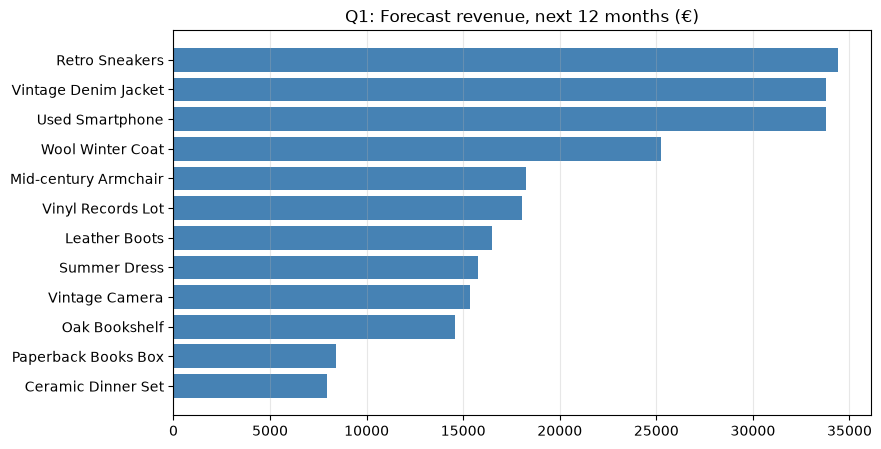

In [9]:
d = summary.sort_values("fc_revenue")
plt.figure(figsize=(9, 5))
plt.barh(d["product"], d["fc_revenue"], color="steelblue")
plt.title("Q1: Forecast revenue, next 12 months (€)")
plt.grid(axis="x", alpha=.3)
plt.show()

### Q2. Which products are growing and which are shrinking?
**Finding:** Paperback Books Box +18%, Oak Bookshelf +11%, Ceramic Dinner Set +6%. The Mid-century Armchair is the only clear decline (−10%).
**Action:** source more books and bookshelves, and review the armchair's price and sourcing.

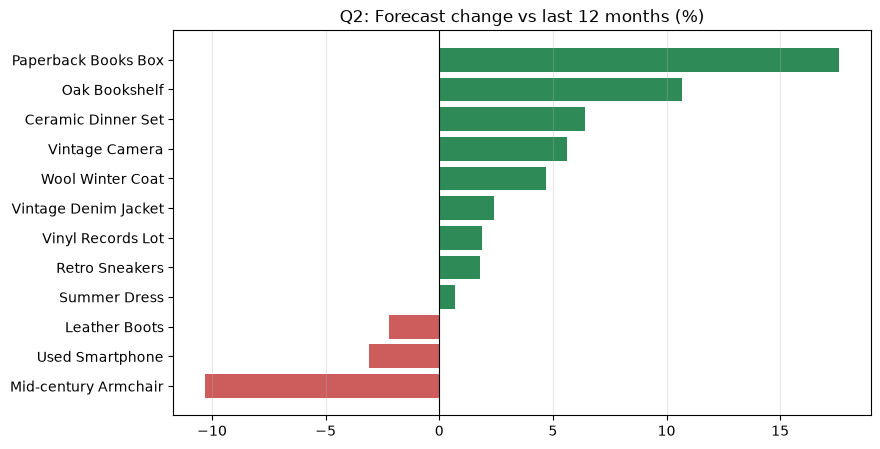

In [10]:
d = summary.sort_values("change_%")
plt.figure(figsize=(9, 5))
plt.barh(d["product"], d["change_%"], color=["seagreen" if v >= 0 else "indianred" for v in d["change_%"]])
plt.axvline(0, color="k", lw=.8)
plt.title("Q2: Forecast change vs last 12 months (%)")
plt.grid(axis="x", alpha=.3)
plt.show()

### Q3. When should we stock up?
**Finding:** the whole store peaks in October and November and is quietest in March, but every product has its own season (coats in Nov, sneakers in May, jackets in Aug, records in Dec).
**Action:** buy winter coats from September and sneakers from March.

**Note:** each row is compared with its own average, so small products are visible too. Darker = busier month.

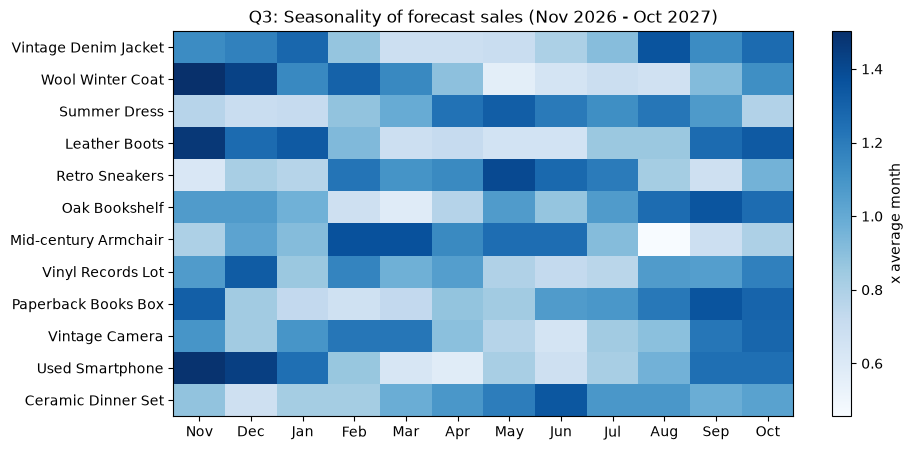

Busiest month: Oct 515 | Quietest: Mar 419


In [11]:
matrix = np.array([r["fc"].round().values for r in results], dtype=float)
idx = matrix / matrix.mean(axis=1, keepdims=True)
months = pd.date_range("2026-11-01", periods=12, freq="MS").strftime("%b")

plt.figure(figsize=(10, 5))
plt.imshow(idx, cmap="Blues", aspect="auto")
plt.xticks(range(12), months)
plt.yticks(range(len(results)), [r["product"] for r in results])
plt.colorbar(label="x average month")
plt.title("Q3: Seasonality of forecast sales (Nov 2026 - Oct 2027)")
plt.show()

total = matrix.sum(axis=0)
print("Busiest month:", months[total.argmax()], int(total.max()), "| Quietest:", months[total.argmin()], int(total.min()))

### Q4. Which forecasts can we trust?
**Finding:** clothing is the most reliable (error about 13–17%). Armchair and Vintage Camera are above 40% because they sell only 6–10 a month, so one extra sale shifts everything. In the backtest the model was too low for most products.
**Action:** plan stock from the clothing forecasts, treat furniture and cameras as rough ranges, and order a bit more than the model says.

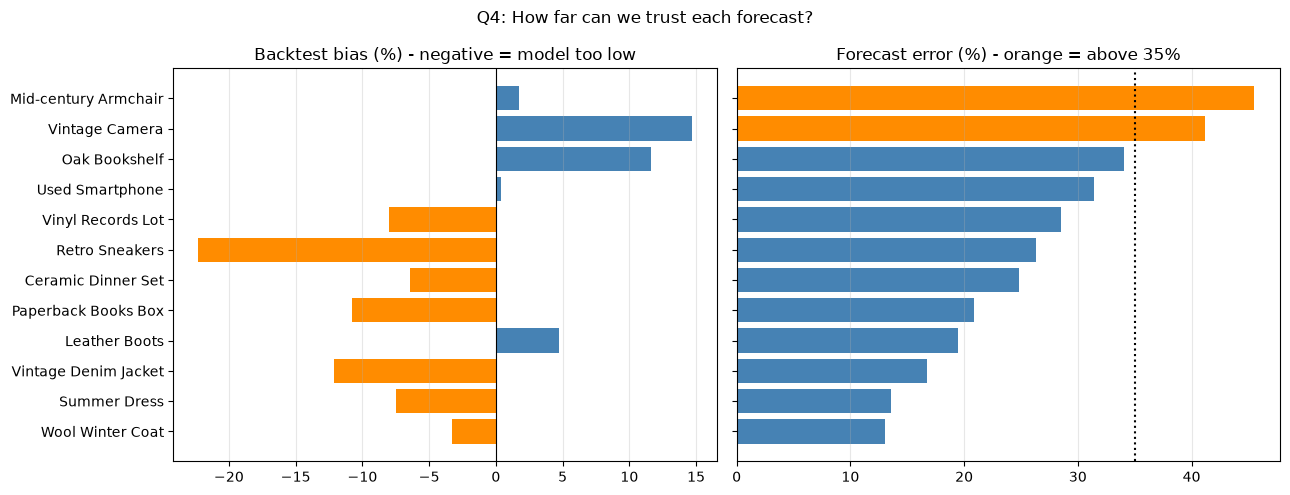

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
d = summary.sort_values("error_%")
ax[0].barh(d["product"], d["bias_%"], color=["steelblue" if v >= 0 else "darkorange" for v in d["bias_%"]])
ax[0].axvline(0, color="k", lw=.8)
ax[0].set_title("Backtest bias (%) - negative = model too low")
ax[1].barh(d["product"], d["error_%"], color=["darkorange" if v > 35 else "steelblue" for v in d["error_%"]])
ax[1].axvline(35, color="k", ls=":")
ax[1].set_title("Forecast error (%) - orange = above 35%")
for a in ax:
    a.grid(axis="x", alpha=.3)
plt.suptitle("Q4: How far can we trust each forecast?")
plt.tight_layout()
plt.show()

## 10. Forecast for one product
**Note:** solid = real sales, dotted = backtest, dashed = forecast. Change the name to see any other product (names are in `summary['product']`).

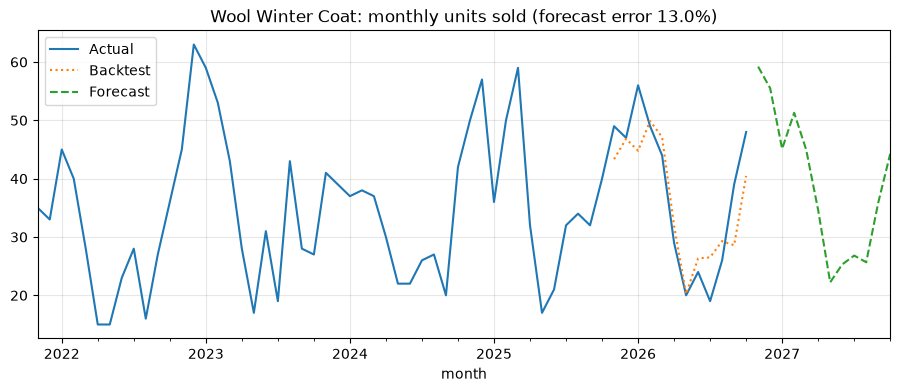

In [13]:
def plot(name):
    r = next(x for x in results if x["product"] == name)
    plt.figure(figsize=(11, 4))
    r["hist"].iloc[-60:].plot(label="Actual")
    r["bt"].plot(style=":", label="Backtest")
    r["fc"].plot(style="--", label="Forecast")
    plt.title(f"{name}: monthly units sold (forecast error {r['mape']:.1f}%)")
    plt.legend(); plt.grid(alpha=.3); plt.show()

plot("Wool Winter Coat")

## 11. Conclusions
- The store is forecast to earn about **€242k** in the next 12 months (+4% vs 2025).
- **Sneakers, denim jackets and smartphones** bring the most revenue; **books and bookshelves** grow fastest; the **armchair** shrinks.
- Demand is seasonal, so stock should follow each product's season, not the store average.
- The ML model beats the simple "same month last year" rule on **10 of 12 products** (average error 26% vs 30%). It does not on the **armchair** and the **camera**.
- Clothing forecasts are reliable; furniture and cameras are too small to predict well.
- The model tends to be too low for growing products, so order a little more than it says.
- **Next step:** add a trend feature or compare with Holt-Winters to reduce that bias.